# 트랜스포머 실습 2: 기온 예측을 트랜스포머로 (RNN · LSTM · GRU와 비교)

RNN 실습 4와 **같은 데이터·같은 분할·같은 윈도우(30일)**, 모델만 트랜스포머 인코더로 바꿈

| 순서 | 내용 | 시간 |
|---|---|---|
| 1 | 데이터 준비 (실습 4와 같음) | 3분 |
| 2 | 트랜스포머 모델: 모양 따라가기 | 7분 |
| 3 | 학습·평가, RNN 계열과 비교 | 7분 |
| 4 | 어텐션 맵: 어느 날을 보고 예측하나 | 5분 |
| 5 | 위치 인코딩을 빼면? | 8분 |
| 6 | 문제 (코드를 직접 고쳐 보기) | 남는 시간·과제 |

데이터: 호주 멜버른 일별 최저기온 1981~1990년 (3,650일)

In [1]:
import math
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(URL, parse_dates=["Date"])
print(df.shape)

(3650, 2)


## 1. 데이터 준비 (RNN 실습 4와 같음)
시간순 분할(train 1981~1988 / val 1989 / test 1990) → train 기준 0~1 정규화 → 지난 30일로 다음 날 예측

In [2]:
temp = torch.tensor(df["Temp"].values, dtype=torch.float32)
year = df["Date"].dt.year.values
i_val, i_test = (year < 1989).sum(), (year < 1990).sum()

t_min, t_max = temp[:i_val].min(), temp[:i_val].max()      # train 기준
scale = lambda v: (v - t_min) / (t_max - t_min)
unscale = lambda v: v * (t_max - t_min) + t_min
s = scale(temp)

WINDOW = 30
def make_windows(start, end):
    idx = range(max(start, WINDOW), end)
    X = torch.stack([s[i - WINDOW:i] for i in idx]).unsqueeze(-1)   # (개수, 30, 1)
    y = torch.stack([s[i] for i in idx]).unsqueeze(-1)              # (개수, 1)
    return X, y

X_train, y_train = make_windows(0, i_val)
X_val, y_val = make_windows(i_val, i_test)
X_test, y_test = make_windows(i_test, len(s))
print("X_train", tuple(X_train.shape), "X_val", tuple(X_val.shape), "X_test", tuple(X_test.shape))

def mae_celsius(pred, y):
    return (unscale(pred) - unscale(y)).abs().mean().item()
print(f"기준선(내일 = 오늘) test MAE: {mae_celsius(X_test[:, -1, :], y_test):.2f} °C")

X_train (2890, 30, 1) X_val (365, 30, 1) X_test (365, 30, 1)
기준선(내일 = 오늘) test MAE: 2.02 °C


## 2. 트랜스포머 모델
RNN은 `nn.RNN` 하나였지만, 트랜스포머는 4단계

| 단계 | 코드 | 모양 (배치 64) |
|---|---|---|
| ① 입력 임베딩: 기온 1개 → 벡터 32개 | `nn.Linear(1, 32)` | (64, 30, 1) → (64, 30, 32) |
| ② 위치 인코딩 더하기 (학습형) | `nn.Parameter(1, 30, 32)` | (64, 30, 32) |
| ③ 인코더 블록 2개 (어텐션 + FFN) | `nn.TransformerEncoder` | (64, 30, 32) |
| ④ 마지막 날(오늘) 자리 → 예측 | `nn.Linear(32, 1)` | (64, 32) → (64, 1) |

- 기온은 단어가 아니라 숫자라서 `nn.Embedding` 대신 `nn.Linear(1, 32)`로 벡터를 만듦
- 위치 인코딩은 sin·cos 대신 **학습하는 위치 벡터** 사용 (`nn.Parameter`). 둘 다 많이 씀

In [3]:
class TempTransformer(nn.Module):
    def __init__(self, d_model=32, nhead=4, num_layers=2, use_pos=True):
        super().__init__()
        self.inp = nn.Linear(1, d_model)                                  # ① 입력 임베딩
        self.pos = nn.Parameter(torch.zeros(1, WINDOW, d_model))          # ② 위치 벡터 (학습)
        self.use_pos = use_pos
        layer = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=2 * d_model,
                                           dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers)          # ③ 인코더 블록 × 2
        self.fc = nn.Linear(d_model, 1)                                   # ④ 출력
    def forward(self, x):
        h = self.inp(x)
        if self.use_pos:
            h = h + self.pos
        h = self.encoder(h)
        return self.fc(h[:, -1, :])                                       # 마지막 날 자리만

model = TempTransformer()
xb = X_train[:64]
h1 = model.inp(xb); h2 = h1 + model.pos; h3 = model.encoder(h2); out = model.fc(h3[:, -1, :])
for name, t in [("입력 x", xb), ("① 임베딩", h1), ("② + 위치", h2), ("③ 인코더", h3), ("④ 출력", out)]:
    print(f"{name:10s} {tuple(t.shape)}")
print("파라미터 수:", sum(p.numel() for p in model.parameters()))

입력 x       (64, 30, 1)
① 임베딩      (64, 30, 32)
② + 위치     (64, 30, 32)
③ 인코더      (64, 30, 32)
④ 출력       (64, 1)
파라미터 수: 18145


## 3. 학습·평가
학습 함수는 실습 4와 같음 (Adam, lr 0.001, 배치 64, 30 에폭, val MAE가 가장 좋을 때 저장)

In [4]:
def train_model(make_model, name, epochs=30):
    torch.manual_seed(0)
    model = make_model()
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
    best = float("inf")
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            val_mae = mae_celsius(model(X_val), y_val)
        if val_mae < best:
            best = val_mae
            torch.save(model.state_dict(), f"best_{name}.pt")
        if epoch % 10 == 0:
            print(f"[{name}] epoch {epoch:2d} | val MAE {val_mae:.2f} °C")
    model.load_state_dict(torch.load(f"best_{name}.pt"))
    model.eval()
    with torch.no_grad():
        test_mae = mae_celsius(model(X_test), y_test)
    print(f"[{name}] 가장 좋은 val MAE {best:.2f} °C → test MAE {test_mae:.2f} °C")
    return model, test_mae

tf_model, tf_mae = train_model(lambda: TempTransformer(), "transformer")

[transformer] epoch 10 | val MAE 1.87 °C


[transformer] epoch 20 | val MAE 1.74 °C


[transformer] epoch 30 | val MAE 1.79 °C
[transformer] 가장 좋은 val MAE 1.72 °C → test MAE 1.76 °C


방법           test MAE (°C)      파라미터 수
기준선                   2.02           -
RNN                   1.74       1,153
LSTM                  1.77       4,513
GRU                   1.76       3,393
Transformer           1.76      18,145


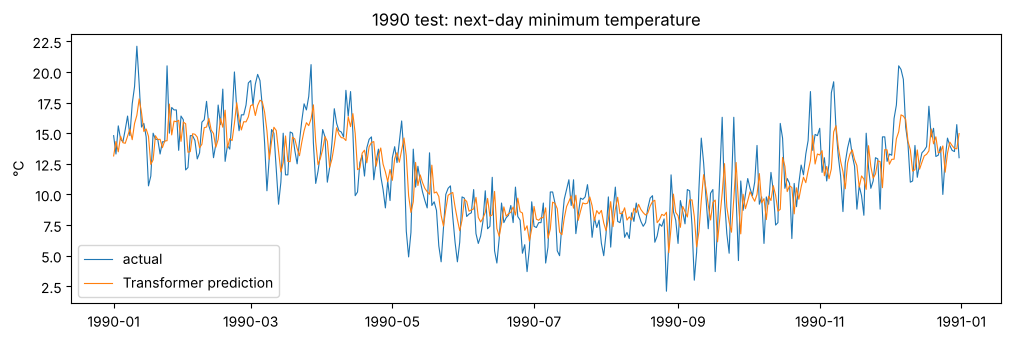

In [5]:
count = lambda m: sum(p.numel() for p in m.parameters())
# RNN·LSTM·GRU는 RNN 실습 4의 결과 (같은 데이터·같은 설정)
results = [("기준선", 2.02, "-"), ("RNN", 1.74, "1,153"), ("LSTM", 1.77, "4,513"), ("GRU", 1.76, "3,393"),
           ("Transformer", tf_mae, f"{count(tf_model):,d}")]
print(f"{'방법':12s}{'test MAE (°C)':>14s}{'파라미터 수':>12s}")
for name, mae, n in results:
    print(f"{name:12s}{mae:>14.2f}{n:>12s}")

with torch.no_grad():
    pred = unscale(tf_model(X_test)).squeeze()
plt.figure(figsize=(12, 3.5))
plt.plot(df["Date"].values[i_test:], unscale(y_test).squeeze(), linewidth=0.8, label="actual")
plt.plot(df["Date"].values[i_test:], pred, linewidth=0.8, label="Transformer prediction")
plt.title("1990 test: next-day minimum temperature"); plt.ylabel("°C"); plt.legend(); plt.show()

- 트랜스포머도 RNN 계열과 거의 같은 MAE, 파라미터는 약 15배
- 실습 4의 결론과 같음: 이 데이터는 **모델이 아니라 입력 정보(기온 1개)가 한계**
- 트랜스포머가 강한 곳: 데이터가 아주 많고 순서가 긴 문장·코드 (번역, 챗봇). 작은 시계열에서는 RNN 계열과 비슷하거나 더 나쁠 수도 있음

## 4. 어텐션 맵: 오늘 자리는 어느 날을 보나
첫 번째 인코더 블록의 어텐션 가중치 꺼내기. test 365개 윈도우의 평균

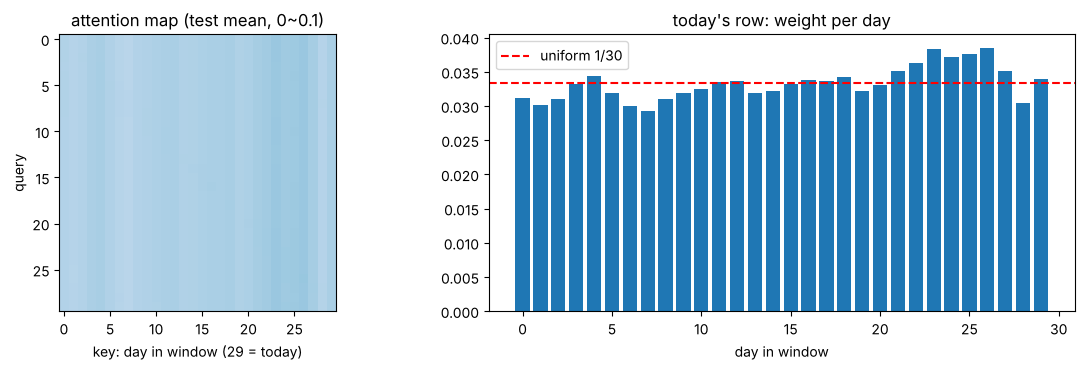

오늘 행 가중치: 최소 0.029, 최대 0.039, 균등이면 0.033


In [6]:
with torch.no_grad():
    h = tf_model.inp(X_test) + tf_model.pos
    _, A = tf_model.encoder.layers[0].self_attn(h, h, h, need_weights=True)   # (365, 30, 30), 헤드 평균
A_mean = A.mean(0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].imshow(A_mean, cmap="Blues", vmin=0, vmax=0.1); axes[0].set_title("attention map (test mean, 0~0.1)")
axes[0].set_xlabel("key: day in window (29 = today)"); axes[0].set_ylabel("query")
axes[1].bar(range(WINDOW), A_mean[-1]); axes[1].axhline(1 / WINDOW, color="red", ls="--", label="uniform 1/30")
axes[1].set_title("today's row: weight per day"); axes[1].set_xlabel("day in window"); axes[1].legend()
plt.tight_layout(); plt.show()
print("오늘 행 가중치: 최소 {:.3f}, 최대 {:.3f}, 균등이면 {:.3f}".format(A_mean[-1].min(), A_mean[-1].max(), 1 / WINDOW))

- 가중치가 거의 고르게 퍼짐 (균등 1/30 ≈ 0.033 근처, 0.029 ~ 0.039). 3~8일 전 쪽이 조금 높은 정도
- 실습 1의 bat처럼 "꼭 봐야 하는 한 단어"가 없는 데이터 → 30일을 넓게 평균 내서 계절 수준을 파악
- 오늘 기온 자체는 **잔차 연결**(입력을 출력에 더하는 길)로 그대로 전달됨

## 5. 위치 인코딩을 빼면?
마지막 날 자리 대신 **30일 전체 평균**(`h.mean(1)`)으로 예측하도록 바꾸고, 위치 벡터 있음/없음을 비교

- 위치 벡터가 없으면 어텐션은 순서를 모름 → 30일을 섞어도 결과가 같음
- 평균을 내면 "어느 날이 오늘인지"도 사라짐

In [7]:
class TempTransformerMean(TempTransformer):
    def forward(self, x):
        h = self.inp(x)
        if self.use_pos:
            h = h + self.pos
        h = self.encoder(h)
        return self.fc(h.mean(1))          # 30일 전체 평균

_, mae_pos = train_model(lambda: TempTransformerMean(use_pos=True), "mean_pos")
_, mae_nopos = train_model(lambda: TempTransformerMean(use_pos=False), "mean_nopos")
print(f"\n위치 인코딩 있음: {mae_pos:.2f} °C | 없음: {mae_nopos:.2f} °C | 기준선: 2.02 °C")

[mean_pos] epoch 10 | val MAE 1.97 °C


[mean_pos] epoch 20 | val MAE 1.72 °C


[mean_pos] epoch 30 | val MAE 1.92 °C
[mean_pos] 가장 좋은 val MAE 1.70 °C → test MAE 1.76 °C


[mean_nopos] epoch 10 | val MAE 2.17 °C


[mean_nopos] epoch 20 | val MAE 2.04 °C


[mean_nopos] epoch 30 | val MAE 2.24 °C
[mean_nopos] 가장 좋은 val MAE 2.02 °C → test MAE 2.04 °C

위치 인코딩 있음: 1.76 °C | 없음: 2.04 °C | 기준선: 2.02 °C


- 위치 인코딩이 없으면 **기준선(내일 = 오늘)보다도 나빠짐**: 30일 중 어느 날이 오늘인지 모르니 "최근 30일 평균" 수준만 맞힘
- 위치 인코딩을 넣으면 마지막 날을 골라낼 수 있어 다시 좋아짐
- RNN은 구조 자체가 순서대로라 위치 인코딩이 필요 없었음

## 6. 문제: 코드를 직접 고쳐 보기
1. 2번 모델에서 `nhead=4`를 1로, `num_layers=2`를 1로 각각 바꿔 test MAE와 파라미터 수 비교하기.
2. `d_model=32`를 64로 바꾸면? 파라미터 수는 몇 배가 될까?
3. 2번 모델(마지막 날 자리 사용)에서 `use_pos=False`로 학습하면? 5번(평균 사용)만큼 나빠질까? 이유는?
4. `nhead=3`으로 바꾸면 에러가 남. 이유는?
5. `WINDOW = 90`으로 바꾸고 1번부터 다시 실행하기. 트랜스포머 MAE는? 학습 시간은 30일보다 몇 배일까?
6. 인코더에 미래 가리기 마스크를 넣어 보기: `forward`에서 `self.encoder(h, mask=nn.Transformer.generate_square_subsequent_mask(WINDOW))`. 결과가 크게 바뀔까?
7. (도전) 입력에 **계절 정보**를 넣어 입력 크기를 1 → 3으로: 날짜의 `sin(2π·일/365)`, `cos(2π·일/365)`. `make_windows`와 `nn.Linear(1, d_model)`을 어떻게 바꿔야 할까?

<details><summary>정답 보기</summary>

1. 실행 결과 예: nhead 1 → 1.75 °C (파라미터 그대로 18,145: 헤드 수는 32차원을 나눠 쓰는 방식만 바꿈), num_layers 1 → 1.75 °C (파라미터 9,601로 약 절반). 이 데이터에서는 작은 모델로도 충분.
2. 실행 결과 예: 1.76 °C 그대로, 파라미터 69,057개로 약 3.8배. 어텐션·FFN 가중치가 d×d 모양이라 d가 2배면 대략 4배.
3. 실행 결과 예: 1.78 °C로 조금만 나빠짐. 마지막 자리 출력에는 오늘 기온이 잔차 연결로 그대로 들어 있어서, 순서를 몰라도 "오늘"은 알 수 있음. 평균을 내면 그것마저 섞여서 사라짐.
4. `d_model`(32)이 `nhead`로 나눠떨어져야 함. 헤드마다 32 / nhead 차원씩 나눠 쓰기 때문.
5. 실행 결과 예: 1.76 °C로 그대로, 시간은 약 4~5배. 어텐션은 단어 쌍마다 계산해서 길이 n이면 n²에 비례 (30² = 900 → 90² = 8,100, 9배)이지만, 다른 계산도 있어서 전체로는 그보다 덜 늘어남.
6. 실행 결과 예: 1.77 °C로 거의 같음. 예측에 쓰는 마지막 날 자리는 마스크가 있어도 앞의 모든 날을 볼 수 있음.
7. 예: `day = torch.tensor(df["Date"].dt.dayofyear.values, dtype=torch.float32)`, `feat = torch.stack([s, torch.sin(2*math.pi*day/365), torch.cos(2*math.pi*day/365)], dim=1)`로 (3650, 3)을 만들고, 윈도우를 `feat[i-WINDOW:i]`로 (개수, 30, 3), 모델은 `nn.Linear(3, d_model)`.
</details>